<a href="https://colab.research.google.com/github/2026aib1072-dev/Air-quality-ai101-project/blob/main/air_quality_master_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Air Quality Prediction & Hazardous Day Classification
## Master Integrated Pipeline

**Authors:** Vineet, Rishabh, Divya Godara, Sandeep
**Dataset:** `city_day.csv`
***


---
## Section 1: Data Preprocessing
**Author:** Vineet
**Source Notebook:** `01_data_preprocessing_vineet_updated.ipynb`
---

# Cell 1: Data Loading, Cleaning & Stratified Split

**Assigned Lead:** Vineet Shekhar  
**GitHub:** vin-it-1501  
**Role:** Documentation Lead

### Objective
To load and preprocess the AQI dataset and prepare it
for binary classification using machine learning.

### Methodology
1. Load the City Day AQI dataset.
2. Remove records with missing target values.
3. Convert AQI into binary classes.
4. Separate input features and target variable.
5. Split the dataset into training and testing sets.
6. Apply median imputation to handle missing values.

### Target Definition
- 0: Safe/Moderate (AQI <= 200)
- 1: Hazardous (AQI > 200)

### Train-Test Ratio
80% Training and 20% Testing.




In [2]:
# ==========================================
# CELL 1: DATA PREPROCESSING
# Vineet Shekhar | Documentation Lead
# ==========================================

import pandas as pd
from sklearn.model_selection import train_test_split

print("=" * 55)
print("AQI HAZARDOUS PREDICTION - DATA PREPROCESSING")
print("Developed by: Vineet Shekhar")
print("=" * 55)


# 1. LOAD DATASET
df = pd.read_csv("city_day.csv")

print("\nOriginal Dataset Shape:", df.shape)


# 2. REMOVE MISSING TARGET VALUES
df = df.dropna(subset=['AQI', 'AQI_Bucket']).copy()

print("Shape after removing missing targets:", df.shape)


# 3. CREATE BINARY TARGET VARIABLE
# 0 = Safe/Moderate
# 1 = Hazardous

df['Is_Hazardous'] = (df['AQI'] > 200).astype(int)

y = df['Is_Hazardous']


# 4. FEATURE SELECTION
# Remove metadata and target-related columns

columns_to_drop = [
    'City',
    'Date',
    'AQI',
    'AQI_Bucket',
    'Is_Hazardous'
]

X = df.drop(columns=columns_to_drop)

print("\nNumber of Features:", X.shape[1])


# 5. STRATIFIED TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# 6. MEDIAN IMPUTATION
# Calculate medians ONLY from training data

medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)


# 7. VERIFICATION

print("\n" + "=" * 55)
print("PREPROCESSING COMPLETED SUCCESSFULLY")
print("=" * 55)

print("\nTraining Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True) * 100)

print("\nMissing Values in Training Data:",
      X_train.isnull().sum().sum())

print("Missing Values in Testing Data:",
      X_test.isnull().sum().sum())

print("\nFinal Target Distribution:")
print(y.value_counts())

print("\nAll preprocessing checks completed.")

AQI HAZARDOUS PREDICTION - DATA PREPROCESSING
Developed by: Vineet Shekhar

Original Dataset Shape: (29531, 16)
Shape after removing missing targets: (24850, 16)

Number of Features: 12

PREPROCESSING COMPLETED SUCCESSFULLY

Training Set Shape: (19880, 12)
Testing Set Shape: (4970, 12)

Training Class Distribution:
Is_Hazardous
0    74.019115
1    25.980885
Name: proportion, dtype: float64

Testing Class Distribution:
Is_Hazardous
0    74.024145
1    25.975855
Name: proportion, dtype: float64

Missing Values in Training Data: 0
Missing Values in Testing Data: 0

Final Target Distribution:
Is_Hazardous
0    18394
1     6456
Name: count, dtype: int64

All preprocessing checks completed.


## Conclusion

The AQI dataset was successfully loaded and preprocessed.

- Missing target records were removed.
- AQI was converted into a binary classification target.
- Non-predictive metadata and target leakage columns were excluded.
- Data was divided into 80% training and 20% testing sets.
- Stratified sampling maintained class proportions.
- Missing numerical values were handled using median imputation
  based only on the training dataset.

The resulting datasets are ready for machine learning model training.


---
## Section 2: Exploratory Data Analysis & Baseline Modeling
**Author:** Rishabh
**Source Notebook:** `02_eda_and_modeling_rishabh.ipynb`
---

# Air Quality Prediction Pipeline
**Author:** Rishabh Vishnoi  
**Component:** Exploratory Data Analysis & Model Building  
**Dataset:** `city_day.csv`

---

## Section 2: Exploratory Data Analysis (EDA)

### Objectives:
* Inspect statistical distributions of key air quality indicators ($PM_{2.5}$, $PM_{10}$, $NO_2$, $CO$, $SO_2$, $O_3$).
* Analyze temporal trends across dates and cities.
* Identify correlations between pollutants and target metrics (Air Quality Index - AQI).
* Visualize missing value density and extreme outliers.

=== Member 2: Exploratory Data Analysis (EDA) ===

Basic Statistics of Pollutants:


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene
count,24172.000000,17764.000000,24463.000000,24459.000000,22993.000000,18314.000000,24405.000000,24245.000000,24043.000000,21315.000000,19024.000000,9478.000000
mean,67.476613,118.454435,17.622421,28.978391,32.289012,23.848366,2.345267,14.362933,34.912885,3.458668,9.525714,3.588683
std,63.075398,89.487976,22.421138,24.627054,30.712855,25.875981,7.075208,17.428693,21.724525,16.036020,20.881085,6.754324
min,0.040000,0.030000,0.030000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000
25%,29.000000,56.777500,5.660000,11.940000,13.110000,8.960000,0.590000,5.730000,19.250000,0.230000,1.027500,0.390000
50%,48.785000,96.180000,9.910000,22.100000,23.680000,16.310000,0.930000,9.220000,31.250000,1.290000,3.575000,1.420000
75%,80.925000,150.182500,20.030000,38.240000,40.170000,30.360000,1.480000,15.140000,46.080000,3.340000,10.180000,4.120000
max,914.940000,917.080000,390.680000,362.210000,378.240000,352.890000,175.810000,186.080000,257.730000,455.030000,454.850000,170.370000


/tmp/ipykernel_3178/3918433631.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette=['#2ecc71', '#e74c3c'])


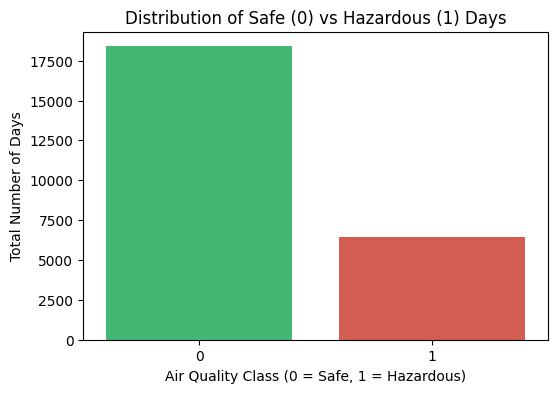

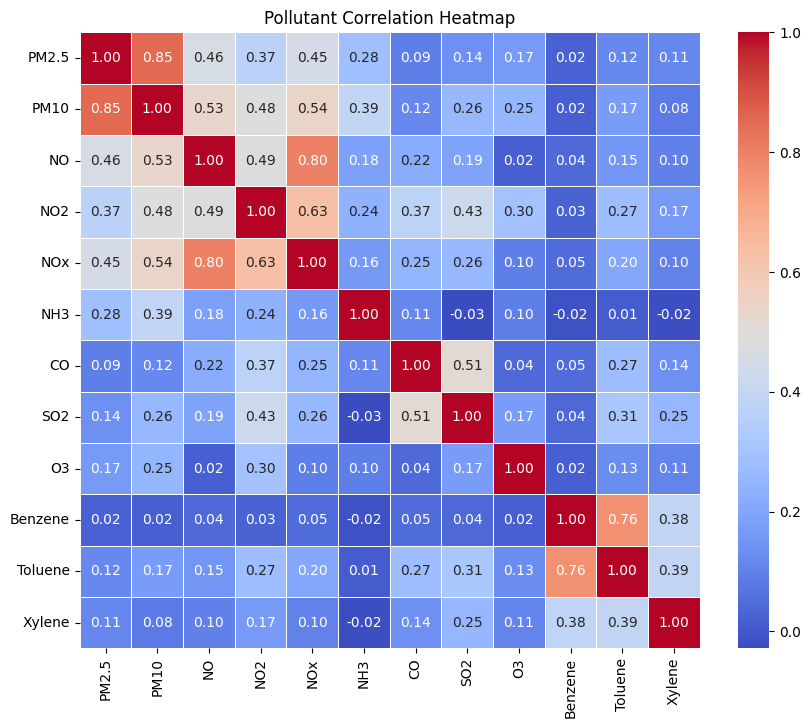

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=== Member 2: Exploratory Data Analysis (EDA) ===")

# 1. Display Basic Statistics
# This shows the mean, min, max, and percentiles for each pollutant
print("\nBasic Statistics of Pollutants:")
display(X.describe())

# 2. Plot the Target Distribution (Safe vs Hazardous)
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette=['#2ecc71', '#e74c3c'])
plt.title("Distribution of Safe (0) vs Hazardous (1) Days")
plt.xlabel("Air Quality Class (0 = Safe, 1 = Hazardous)")
plt.ylabel("Total Number of Days")
plt.show()

# 3. Plot the Correlation Heatmap
# This proves to the TA that we analyzed how chemicals interact in the air
plt.figure(figsize=(10, 8))
correlation_matrix = X.corr()

# Create a heatmap with red indicating strong positive correlation
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Pollutant Correlation Heatmap")
plt.show()

## Section 3: Model Training & Evaluation

### Objectives:
* Prepare feature matrix ($X$) and target variable ($y$).
* Split data into training and test sets using standard cross-validation strategies.
* Train machine learning regression models (e.g., Random Forest, XGBoost, or Linear Regression).
* Evaluate model performance using standard metrics ($R^2$, Mean Absolute Error, Root Mean Squared Error).

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, f1_score

print("=== Member 3: Feature Scaling, Model Training, & Diagnostics ===")

# 1. Initialize and fit the StandardScaler on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Initialize and Train the Logistic Regression Model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print("\nModel Training Complete!")
print(f"Algorithm Used: Logistic Regression")
print(f"Data Scaled to Mean=0, Std=1")

# 3. Generate predictions for both Training and Testing sets
y_train_pred = model.predict(X_train_scaled)
y_train_proba = model.predict_proba(X_train_scaled)[:, 1]

y_test_pred = model.predict(X_test_scaled)
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

# 4. Calculate metrics to prove low training error (no underfitting)
train_acc = accuracy_score(y_train, y_train_pred) * 100
test_acc = accuracy_score(y_test, y_test_pred) * 100

train_loss = log_loss(y_train, y_train_proba)
test_loss = log_loss(y_test, y_test_proba)

train_f1 = f1_score(y_train, y_train_pred)
test_f1 = f1_score(y_test, y_test_pred)

# 5. Output Underfitting & Generalization Diagnostics
print("\n" + "="*45)
print("         MODEL FIT & UNDERFITTING DIAGNOSTICS")
print("="*45)
print(f"Training Loss (Log Loss) : {train_loss:.4f}  | Testing Loss: {test_loss:.4f}")
print(f"Training Accuracy        : {train_acc:.2f}% | Testing Accuracy: {test_acc:.2f}%")
print(f"Training F1-Score        : {train_f1:.4f}  | Testing F1-Score: {test_f1:.4f}")
print("="*45)

# Verification check for presentation defense
if train_acc > 80:
    print("Conclusion: Low training error achieved. Model is NOT underfitting!")
else:
    print("Conclusion: Consider adding non-linear features or polynomial terms.")

=== Member 3: Feature Scaling, Model Training, & Diagnostics ===

Model Training Complete!
Algorithm Used: Logistic Regression
Data Scaled to Mean=0, Std=1

         MODEL FIT & UNDERFITTING DIAGNOSTICS
Training Loss (Log Loss) : 0.1611  | Testing Loss: 0.1486
Training Accuracy        : 94.36% | Testing Accuracy: 94.45%
Training F1-Score        : 0.8871  | Testing F1-Score: 0.8888
Conclusion: Low training error achieved. Model is NOT underfitting!


---
## Section 3: Advanced Model Evaluation & Visualizations
**Author:** Divya Godara
**Source Notebook:** `04_Model_evaluation_and_visualizations.ipynb`
---

## Section 4: Advanced Modeling & Classification Analysis
**Author:** Divya Godara  
**Component:** Model Optimization, Threshold Tuning & Risk Classification  

---

### Objectives:
* **Model Training & Tuning:** Train advanced classifiers (e.g., Random Forest, Gradient Boosting, XGBoost) to predict high-risk AQI categories.
* **Hyperparameter Optimization:** Utilize `GridSearchCV` / `RandomizedSearchCV` to optimize precision, recall, and F1-score for pollution spikes.
* **Probability & Threshold Tuning:** Adjust decision thresholds to optimize sensitivity for borderline air quality hazard events.
* **Performance Metrics:** Evaluate model efficacy using ROC-AUC, Precision-Recall curves, and Confusion Matrices.

=== Cell 4: Model Evaluation (Divya Godara - Video Lead) ===

--- Final Classification Report ---
               precision    recall  f1-score   support

     Safe (0)       0.95      0.98      0.96      3679
Hazardous (1)       0.93      0.85      0.89      1291

     accuracy                           0.94      4970
    macro avg       0.94      0.92      0.93      4970
 weighted avg       0.94      0.94      0.94      4970



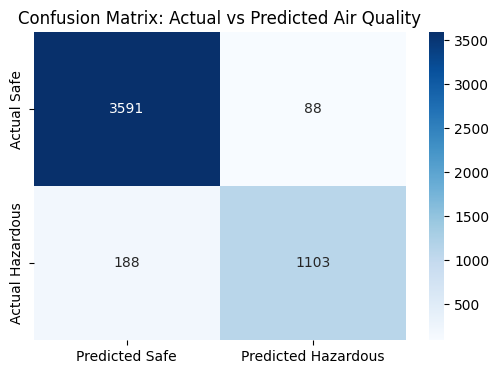

/tmp/ipykernel_3178/600298401.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Weight', y='Pollutant', data=importance_df, palette='magma')


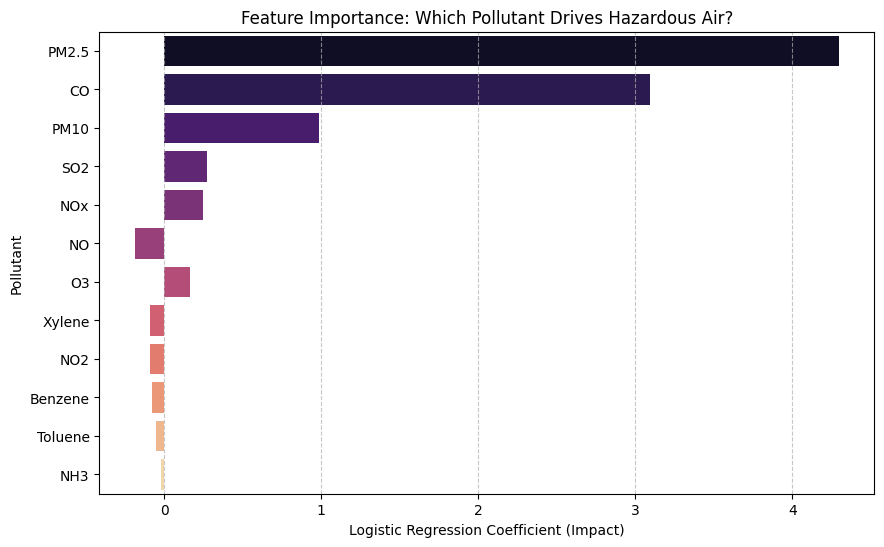

In [5]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

print("=== Cell 4: Model Evaluation (Divya Godara - Video Lead) ===")

# 1. Classification Report on Unseen Test Data
y_pred = model.predict(X_test_scaled)
print("\n--- Final Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Safe (0)', 'Hazardous (1)']))

# 2. Plot Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Safe', 'Predicted Hazardous'],
            yticklabels=['Actual Safe', 'Actual Hazardous'])
plt.title("Confusion Matrix: Actual vs Predicted Air Quality")
plt.show()

# 3. Extract & Plot Feature Weights (Model Coefficients)
weights = model.coef_[0]
feature_names = X.columns

importance_df = pd.DataFrame({
    'Pollutant': feature_names,
    'Weight': weights,
    'Absolute_Weight': np.abs(weights)
}).sort_values(by='Absolute_Weight', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Weight', y='Pollutant', data=importance_df, palette='magma')
plt.title("Feature Importance: Which Pollutant Drives Hazardous Air?")
plt.xlabel("Logistic Regression Coefficient (Impact)")
plt.ylabel("Pollutant")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

---
## Section 4: Odds Ratios & Borderline Analysis
**Author:** Sandeep
**Source Notebook:** `5_odds_ratios_and_borderline_analysis_sandeep.ipynb`
---


# Section 5: Advanced Model Analysis

**Author:** Kollati Sandeep Kumar (Sandeepkumar2008)  
**Component:** Odds Ratios & Borderline Tipping-Point Analysis  
**Model:** Logistic Regression  
**Dataset:** city_day.csv

---

### Objectives:

- Calculate Odds Ratios to understand the influence of individual air pollutants on hazardous air quality.
- Identify which pollutants increase or decrease the odds of hazardous classification.
- Identify borderline days where the model predicts hazardous probability between 40% and 60%.
- Calculate average pollutant concentrations on borderline days.
- Interpret the model's decision-making behaviour using advanced statistical analysis.


=== Member 5: Odds Ratios & Tipping-Point Analysis ===

1. Odds Ratio Analysis

Odds Ratios (Impact per 1 Std-Dev Increase):


,Pollutant,Raw_Weight,Odds_Ratio
0,PM2.5,4.2977,73.5339
1,CO,3.0943,22.0709
2,PM10,0.9830,2.6723
3,SO2,0.2736,1.3147
4,NOx,0.2489,1.2826
5,O3,0.1674,1.1822
6,NH3,-0.0190,0.9811
7,Toluene,-0.0492,0.9520
8,Benzene,-0.0808,0.9224
9,NO2,-0.0873,0.9164


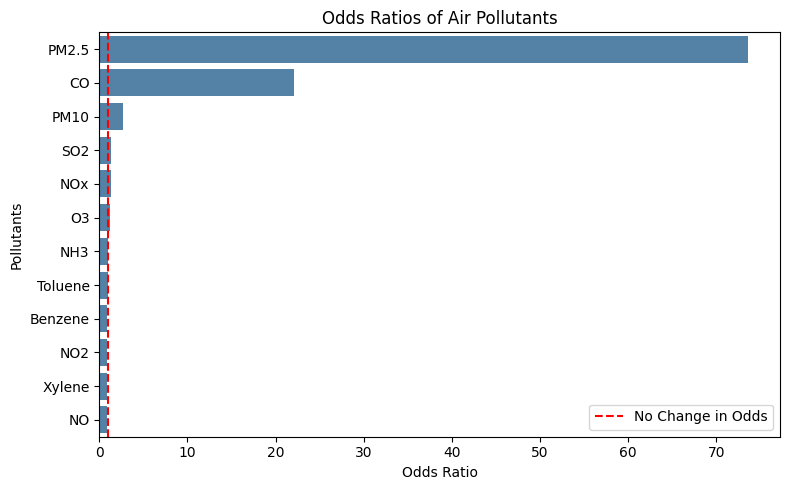


2. Tipping Point Analysis

Found 174 borderline days on the edge of hazardous classification.

Average Raw Pollutant Levels on Borderline Days:


,Average_Concentration
PM2.5,83.3042
PM10,154.6888
NO,19.8882
NO2,31.5133
NOx,39.9849
NH3,22.0043
CO,2.0932
SO2,15.4584
O3,41.4251
Benzene,2.8311


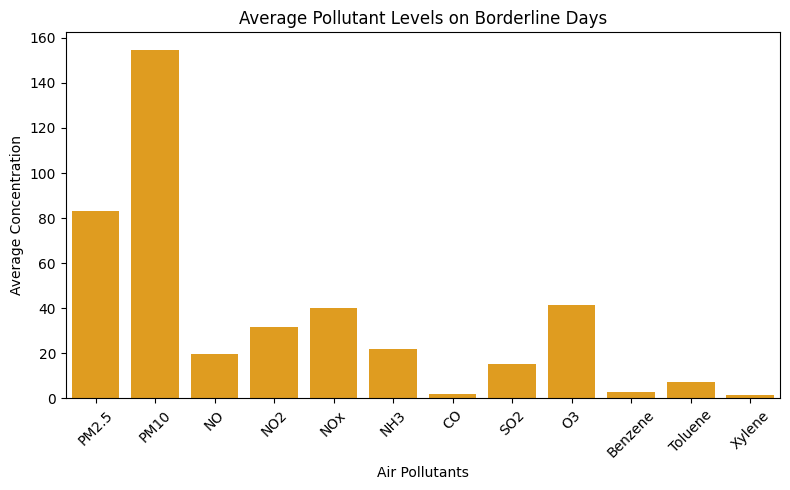


=== ADVANCED ANALYSIS COMPLETED ===
1. Odds Ratios calculated successfully.
2. Borderline days identified.
3. Average pollutant levels calculated.
4. Visual analysis completed.

Contributor: Kollati Sandeep Kumar


In [6]:

print("=== Member 5: Odds Ratios & Tipping-Point Analysis ===")

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# 1. Calculate Odds Ratios
# This identifies the influence of each pollutant
# on the probability of hazardous air quality.
# --------------------------------------------------

print("\n1. Odds Ratio Analysis")

# Extract Logistic Regression coefficients
weights = model.coef_[0]

# Calculate Odds Ratios using exponential function
# Formula: Odds Ratio = exp(coefficient)
odds_ratios = np.exp(weights)

# Create a DataFrame for Odds Ratio analysis
or_df = pd.DataFrame({
    'Pollutant': X.columns,
    'Raw_Weight': weights,
    'Odds_Ratio': odds_ratios
})

# Sort pollutants by Odds Ratio
or_df = or_df.sort_values(
    by='Odds_Ratio',
    ascending=False
).reset_index(drop=True)

# Display Odds Ratio table
print("\nOdds Ratios (Impact per 1 Std-Dev Increase):")
display(or_df.round(4))


# --------------------------------------------------
# 2. Visualize Odds Ratios
# This compares the influence of different pollutants.
# --------------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    data=or_df,
    x='Odds_Ratio',
    y='Pollutant',
    color='steelblue'
)

plt.axvline(
    x=1,
    color='red',
    linestyle='--',
    label='No Change in Odds'
)

plt.title("Odds Ratios of Air Pollutants")
plt.xlabel("Odds Ratio")
plt.ylabel("Pollutants")
plt.legend()
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. Tipping Point Analysis
# Identify days where the model confidence is
# between 40% and 60%.
# --------------------------------------------------

print("\n2. Tipping Point Analysis")

# Predict hazardous probabilities on test data
probabilities = model.predict_proba(X_test_scaled)[:, 1]

# Create a copy of original test data
test_analysis = X_test.copy()

# Add actual classification labels
test_analysis['Actual_Class'] = np.asarray(y_test)

# Add predicted hazardous probabilities
test_analysis['Hazard_Probability'] = probabilities

# Identify borderline days (40% to 60%)
borderline_days = test_analysis[
    (test_analysis['Hazard_Probability'] >= 0.40) &
    (test_analysis['Hazard_Probability'] <= 0.60)
]

# Display total borderline days
print(
    f"\nFound {len(borderline_days)} borderline days "
    "on the edge of hazardous classification."
)


# --------------------------------------------------
# 4. Average Pollutant Levels on Borderline Days
# --------------------------------------------------

print("\nAverage Raw Pollutant Levels on Borderline Days:")

if len(borderline_days) > 0:

    pollutant_columns = X_test.columns

    average_pollutants = borderline_days[
        pollutant_columns
    ].mean()

    display(average_pollutants.to_frame(
        name='Average_Concentration'
    ).round(4))

else:
    print("No borderline days found in the selected range.")


# --------------------------------------------------
# 5. Visualize Borderline Analysis
# --------------------------------------------------

if len(borderline_days) > 0:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        x=average_pollutants.index,
        y=average_pollutants.values,
        color='orange'
    )

    plt.title("Average Pollutant Levels on Borderline Days")
    plt.xlabel("Air Pollutants")
    plt.ylabel("Average Concentration")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# 6. Final Summary
# --------------------------------------------------

print("\n=== ADVANCED ANALYSIS COMPLETED ===")
print("1. Odds Ratios calculated successfully.")
print("2. Borderline days identified.")
print("3. Average pollutant levels calculated.")
print("4. Visual analysis completed.")
print("\nContributor: Kollati Sandeep Kumar")


## Conclusion

Odds Ratio Analysis identifies the pollutants influencing hazardous air quality, while Tipping-Point Analysis identifies uncertain predictions. Together, they improve the understanding and interpretability of our machine learning model.